In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

from scipy.optimize import least_squares
from scipy.stats import norm

print("Ready to build the Tata Steel Merton model!")

Ready to build the Tata Steel Merton model!


Observations: 247
Last trading date: 2026-03-30
Annualised equity volatility: 30.53%


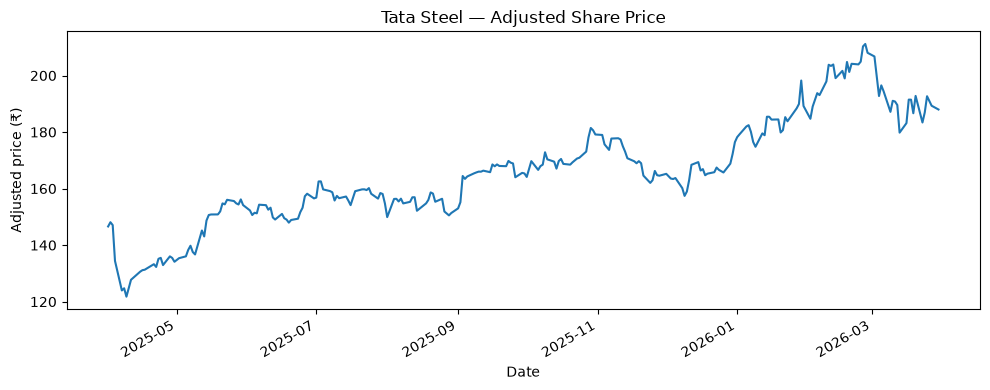

In [2]:
valuation_date = pd.Timestamp("2026-03-31")

# Yahoo Finance's end date is exclusive.
prices = yf.download(
    "TATASTEEL.NS",
    start="2025-04-01",
    end="2026-04-01",
    auto_adjust=True,
    progress=False,
)

if prices.empty:
    raise ValueError("No prices downloaded. Share the output with me.")

# Handles both ordinary and multi-level column formats.
close = prices["Close"]

if isinstance(close, pd.DataFrame):
    close = close.iloc[:, 0]

close = close.dropna()

# Daily percentage changes measured using logarithms.
daily_returns = np.log(close / close.shift(1)).dropna()

# Convert daily volatility into annual volatility.
equity_volatility = daily_returns.std(ddof=1) * np.sqrt(252)

print(f"Observations: {len(close)}")
print(f"Last trading date: {close.index[-1].date()}")
print(f"Annualised equity volatility: {equity_volatility:.2%}")

close.plot(
    figsize=(10, 4),
    title="Tata Steel — Adjusted Share Price",
    ylabel="Adjusted price (₹)",
    xlabel="Date",
)

plt.tight_layout()
plt.show()

In [3]:
raw_prices = yf.download(
    "TATASTEEL.NS",
    start="2026-03-25",
    end="2026-04-01",
    auto_adjust=False,
    progress=False,
)

raw_close = raw_prices["Close"]

if isinstance(raw_close, pd.DataFrame):
    raw_close = raw_close.iloc[:, 0]

raw_close = raw_close.dropna()

if raw_close.empty:
    raise ValueError("No closing prices downloaded.")

share_price = float(raw_close.iloc[-1])

print(f"Price date: {raw_close.index[-1].date()}")
print(f"Actual closing price: ₹{share_price:.2f}")

Price date: 2026-03-30
Actual closing price: ₹191.86


In [4]:
# Historical share count from the FY2025–26 annual report.
shares_outstanding = 12_471_847_611

# share_price is the ₹191.86 closing price downloaded earlier.
equity_value_rupees = share_price * shares_outstanding

# Convert rupees into crore: 1 crore = 10 million.
E = equity_value_rupees / 10_000_000

print(f"Share price: ₹{share_price:.2f}")
print(f"Shares outstanding: {shares_outstanding:,}")
print(f"Equity market value: ₹{E:,.2f} crore")
print(f"Equity volatility: {equity_volatility:.2%}")

Share price: ₹191.86
Shares outstanding: 12,471,847,611
Equity market value: ₹239,284.87 crore
Equity volatility: 30.53%


In [5]:
current_borrowings = 21_202.72
noncurrent_borrowings = 63_753.67

# Simplification: treat all borrowings as one payment in one year.
# Lease liabilities are excluded from this first version.
D = current_borrowings + noncurrent_borrowings
T = 1.0

print(f"Debt proxy: ₹{D:,.2f} crore")
print(f"Model horizon: {T:.0f} year")

Debt proxy: ₹84,956.39 crore
Model horizon: 1 year


In [6]:
r = 0.06  # Illustrative continuously compounded annual rate.


def merton_residuals(parameters, E, D, r, T, sigma_E):
    V, sigma_V = parameters

    d1 = (
        np.log(V / D) + (r + 0.5 * sigma_V**2) * T
    ) / (sigma_V * np.sqrt(T))

    d2 = d1 - sigma_V * np.sqrt(T)

    estimated_equity = (
        V * norm.cdf(d1)
        - D * np.exp(-r * T) * norm.cdf(d2)
    )

    estimated_equity_volatility = (
        norm.cdf(d1) * sigma_V * V / E
    )

    # Relative errors keep both equations on comparable scales.
    return [
        (estimated_equity - E) / E,
        (estimated_equity_volatility - sigma_E) / sigma_E,
    ]


initial_asset_value = E + D
initial_asset_volatility = equity_volatility * E / (E + D)

solution = least_squares(
    merton_residuals,
    x0=[initial_asset_value, initial_asset_volatility],
    bounds=([E, 0.000001], [np.inf, np.inf]),
    args=(E, D, r, T, equity_volatility),
    x_scale="jac",
    ftol=1e-12,
    xtol=1e-12,
    gtol=1e-12,
)

if (
    not solution.success
    or np.max(np.abs(solution.fun)) > 1e-6
):
    raise ValueError("Model did not fit successfully. Share the output.")

V, asset_volatility = solution.x

print(f"Estimated asset value: ₹{V:,.2f} crore")
print(f"Estimated asset volatility: {asset_volatility:.2%}")
print(f"Largest relative fitting error: {np.max(np.abs(solution.fun)):.2e}")

Estimated asset value: ₹319,293.78 crore
Estimated asset volatility: 22.88%
Largest relative fitting error: 0.00e+00


In [7]:
# Distance to default under risk-neutral assumptions.
distance_to_default_q = (
    np.log(V / D)
    + (r - 0.5 * asset_volatility**2) * T
) / (asset_volatility * np.sqrt(T))

# Probability that assets finish below D at the horizon.
default_probability_q = norm.cdf(-distance_to_default_q)

results = pd.DataFrame({
    "Metric": [
        "Equity market value (₹ crore)",
        "Debt proxy (₹ crore)",
        "Estimated asset value (₹ crore)",
        "Equity volatility",
        "Asset volatility",
        "Risk-neutral distance to default",
        "Risk-neutral default probability",
    ],
    "Value": [
        f"{E:,.2f}",
        f"{D:,.2f}",
        f"{V:,.2f}",
        f"{equity_volatility:.2%}",
        f"{asset_volatility:.2%}",
        f"{distance_to_default_q:.2f}",
        f"{default_probability_q:.8%}",
    ],
})

display(results)

print(
    "Default probability in scientific notation: "
    f"{default_probability_q:.4e}"
)

,Metric,Value
0,Equity market value (₹ crore),"239,284.87"
1,Debt proxy (₹ crore),"84,956.39"
2,Estimated asset value (₹ crore),"319,293.78"
3,Equity volatility,30.53%
4,Asset volatility,22.88%
5,Risk-neutral distance to default,5.93
6,Risk-neutral default probability,0.00000015%


Default probability in scientific notation: 1.4738e-09


In [8]:
def analyse_scenario(name, price_fall, volatility_multiplier):
    stressed_E = E * (1 - price_fall)
    stressed_sigma_E = equity_volatility * volatility_multiplier

    fit = least_squares(
        merton_residuals,
        x0=[
            stressed_E + D,
            stressed_sigma_E * stressed_E / (stressed_E + D),
        ],
        bounds=([stressed_E, 0.000001], [np.inf, np.inf]),
        args=(stressed_E, D, r, T, stressed_sigma_E),
        x_scale="jac",
        ftol=1e-12,
        xtol=1e-12,
        gtol=1e-12,
    )

    if not fit.success or np.max(np.abs(fit.fun)) > 1e-6:
        raise ValueError(f"Model fitting failed for: {name}")

    stressed_V, stressed_sigma_V = fit.x

    d2 = (
        np.log(stressed_V / D)
        + (r - 0.5 * stressed_sigma_V**2) * T
    ) / (stressed_sigma_V * np.sqrt(T))

    return {
        "Scenario": name,
        "Share price (₹)": share_price * (1 - price_fall),
        "Equity volatility (%)": stressed_sigma_E * 100,
        "Asset value (₹ crore)": stressed_V,
        "Risk-neutral distance": d2,
        "Risk-neutral PD (%)": norm.cdf(-d2) * 100,
    }


scenarios = pd.DataFrame([
    analyse_scenario("Base case", 0.00, 1.00),
    analyse_scenario("Price down 10%", 0.10, 1.00),
    analyse_scenario("Price down 30%", 0.30, 1.00),
    analyse_scenario("Price down 30%; volatility up 50%", 0.30, 1.50),
])

display(
    scenarios.style.format({
        "Share price (₹)": "{:,.2f}",
        "Equity volatility (%)": "{:.2f}",
        "Asset value (₹ crore)": "{:,.2f}",
        "Risk-neutral distance": "{:.2f}",
        "Risk-neutral PD (%)": "{:.8f}",
    })
)

,Scenario,Share price (₹),Equity volatility (%),Asset value (₹ crore),Risk-neutral distance,Risk-neutral PD (%)
0,Base case,191.86,30.53,"319,293.78",5.93,0.00000015
1,Price down 10%,172.67,30.53,"295,365.30",5.76,0.00000043
2,Price down 30%,134.30,30.53,"247,508.32",5.36,0.00000410
3,Price down 30%; volatility up 50%,134.30,45.80,"247,506.91",3.49,0.02427296


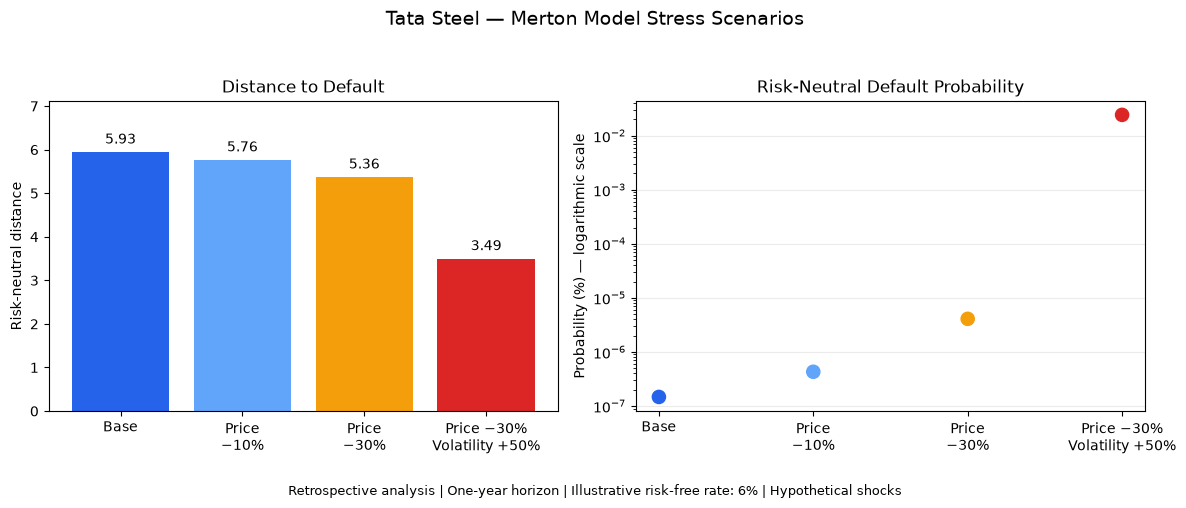

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

labels = [
    "Base",
    "Price\n−10%",
    "Price\n−30%",
    "Price −30%\nVolatility +50%",
]

colors = ["#2563eb", "#60a5fa", "#f59e0b", "#dc2626"]

# Chart 1: distance to default.
bars = axes[0].bar(
    labels,
    scenarios["Risk-neutral distance"],
    color=colors,
)

axes[0].bar_label(bars, fmt="%.2f", padding=4)
axes[0].set_title("Distance to Default")
axes[0].set_ylabel("Risk-neutral distance")
axes[0].set_ylim(
    0,
    scenarios["Risk-neutral distance"].max() * 1.2,
)

# Chart 2: default probabilities span several orders of magnitude.
axes[1].scatter(
    range(len(labels)),
    scenarios["Risk-neutral PD (%)"],
    c=colors,
    s=90,
    zorder=3,
)

axes[1].set_xticks(range(len(labels)))
axes[1].set_xticklabels(labels)
axes[1].set_yscale("log")
axes[1].set_title("Risk-Neutral Default Probability")
axes[1].set_ylabel("Probability (%) — logarithmic scale")
axes[1].grid(axis="y", alpha=0.25)

fig.suptitle("Tata Steel — Merton Model Stress Scenarios", fontsize=14)
fig.text(
    0.5, 0.01,
    "Retrospective analysis | One-year horizon | "
    "Illustrative risk-free rate: 6% | Hypothetical shocks",
    ha="center",
    fontsize=9,
)

plt.tight_layout(rect=[0, 0.06, 1, 0.94])
plt.show()

Under the simplified Merton model, Tata Steel’s baseline risk-neutral distance to default was 5.93. A 30% equity-price decline reduced this to 5.36. Combining that decline with a 50% increase in equity volatility reduced the distance further to 3.49 and increased the one-year risk-neutral default probability to approximately 0.0243%. The results demonstrate sensitivity to equity value and volatility; they are not forecasts of actual default.

In [10]:
from pathlib import Path

tableau_data = scenarios.copy()

# Add useful fields to each scenario.
tableau_data["Company"] = "Tata Steel"
tableau_data["Debt (₹ crore)"] = D
tableau_data["Asset volatility (%)"] = [
    # Recover asset volatility from the fitted volatility equation.
    # We will export it directly from the model in a later refinement.
    np.nan
] * len(tableau_data)

# Remove the placeholder field until we export actual fitted values.
tableau_data = tableau_data.drop(columns=["Asset volatility (%)"])

tableau_data["Scenario order"] = range(len(tableau_data))

output_path = Path("tata_steel_scenarios.csv")
tableau_data.to_csv(output_path, index=False)

print(f"CSV saved here: {output_path.resolve()}")

CSV saved here: /Users/santhosh/tata-steel-merton/tata_steel_scenarios.csv
